# Validation of Second-Order IIR Parametric Equalizer Filters

Implementation based on Van Waterschoot and Moonen (2007).

This notebook evaluates the application of notch and resonance filters
to synthetic ECG-like and audio-like signals.

The analysis includes:
- Time-domain comparison
- Frequency-domain comparison
- Filter frequency response
- Signal quality measurements
- Comparison of different bandwidths

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

from scipy.io import wavfile
from scipy.signal import lfilter, freqz

from design_biquad_filter import design_biquad_filter

In [2]:
fs_ecg, ecg_clean = wavfile.read("signals/ecg_clean.wav")
fs_ecg_noisy, ecg_noisy = wavfile.read("signals/ecg_noisy.wav")

fs_tone, tone_clean = wavfile.read("signals/tone_clean.wav")
fs_tone_noisy, tone_noisy = wavfile.read("signals/tone_noisy.wav")

assert fs_ecg == fs_ecg_noisy
assert fs_tone == fs_tone_noisy

ecg_clean = ecg_clean.astype(float)
ecg_noisy = ecg_noisy.astype(float)

tone_clean = tone_clean.astype(float)
tone_noisy = tone_noisy.astype(float)

print("ECG sampling frequency:", fs_ecg)
print("Tone sampling frequency:", fs_tone)
print("ECG samples:", len(ecg_noisy))
print("Tone samples:", len(tone_noisy))

ECG sampling frequency: 4000
Tone sampling frequency: 4000
ECG samples: 40000
Tone samples: 40000


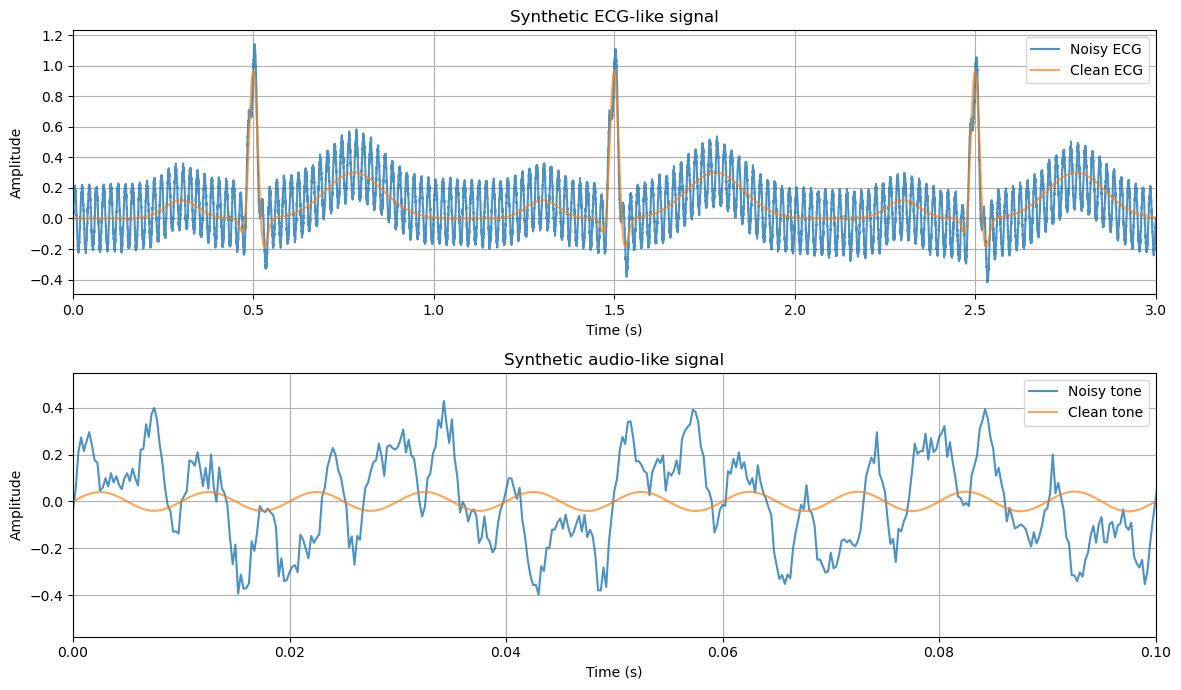

In [3]:
t_ecg = np.arange(len(ecg_noisy)) / fs_ecg
t_tone = np.arange(len(tone_noisy)) / fs_tone

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(t_ecg, ecg_noisy, label="Noisy ECG", alpha=0.8)
axes[0].plot(t_ecg, ecg_clean, label="Clean ECG", alpha=0.7)
axes[0].set_xlim(0, 3)
axes[0].set_title("Synthetic ECG-like signal")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(t_tone, tone_noisy, label="Noisy tone", alpha=0.8)
axes[1].plot(t_tone, tone_clean, label="Clean tone", alpha=0.7)
axes[1].set_xlim(0, 0.1)
axes[1].set_title("Synthetic audio-like signal")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Amplitude")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [4]:
def plot_spectrum(signal, fs, label, ax):
    n = len(signal)

    frequencies = np.fft.rfftfreq(n, d=1/fs)
    spectrum = np.abs(np.fft.rfft(signal)) * 2 / n

    ax.plot(frequencies, spectrum, label=label)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

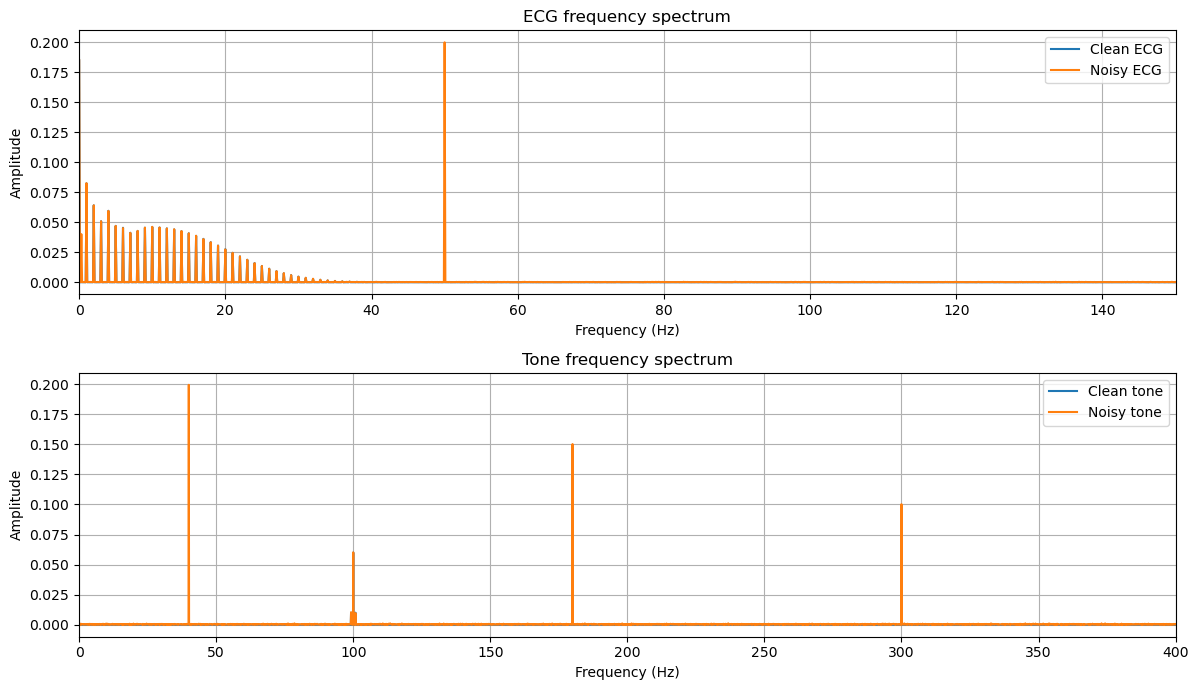

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

plot_spectrum(ecg_clean, fs_ecg, "Clean ECG", axes[0])
plot_spectrum(ecg_noisy, fs_ecg, "Noisy ECG", axes[0])

axes[0].set_xlim(0, 150)
axes[0].set_title("ECG frequency spectrum")
axes[0].legend()

plot_spectrum(tone_clean, fs_tone, "Clean tone", axes[1])
plot_spectrum(tone_noisy, fs_tone, "Noisy tone", axes[1])

axes[1].set_xlim(0, 400)
axes[1].set_title("Tone frequency spectrum")
axes[1].legend()

plt.tight_layout()
plt.show()

In [6]:
# Notch filter
notch_fc = 50
notch_bandwidth = 5
notch_G0 = 1
notch_Gc = 0.1

notch_wc = 2 * math.pi * notch_fc / fs_ecg
notch_B = 2 * math.pi * notch_bandwidth / fs_ecg

b_notch, a_notch = design_biquad_filter(
    notch_G0, notch_Gc, notch_B, notch_wc
)


# Resonance filter
res_fc = 100
res_bandwidth = 10
res_G0 = 1
res_Gc = 5

res_wc = 2 * math.pi * res_fc / fs_tone
res_B = 2 * math.pi * res_bandwidth / fs_tone

b_res, a_res = design_biquad_filter(
    res_G0, res_Gc, res_B, res_wc
)

print("Notch coefficients:")
print("b =", b_notch)
print("a =", a_notch)

print("\nResonance coefficients:")
print("b =", b_res)
print("a =", a_res)

Notch coefficients:
b = [1, -1.9860835901938607, 0.9922400676899621]
a = [1, -1.9163238947423042, 0.9237608317561454]

Resonance coefficients:
b = [0.8710821604807056, -1.5956505464387813, 0.7490599987016078]
a = [1, -1.9598621090160258, 0.9843537217595579]


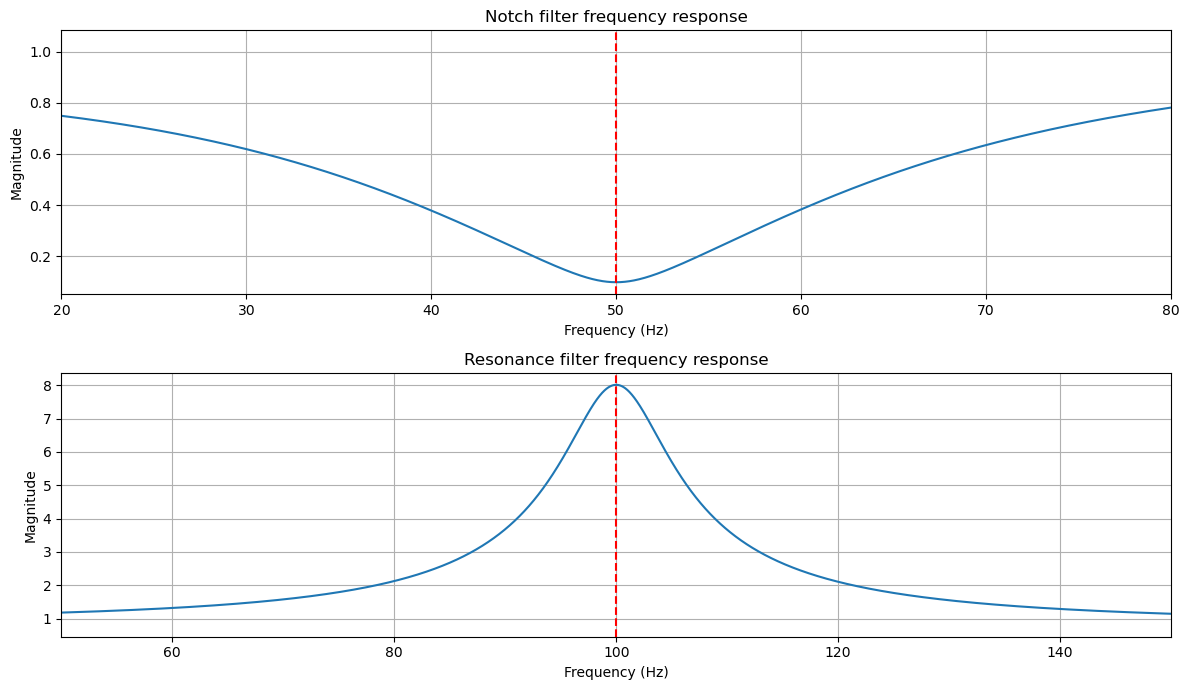

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

f_notch, h_notch = freqz(
    b_notch, a_notch, worN=65536, fs=fs_ecg
)

f_res, h_res = freqz(
    b_res, a_res, worN=65536, fs=fs_tone
)

axes[0].plot(f_notch, np.abs(h_notch))
axes[0].axvline(notch_fc, color="red", linestyle="--")
axes[0].set_xlim(20, 80)
axes[0].set_title("Notch filter frequency response")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Magnitude")
axes[0].grid(True)

axes[1].plot(f_res, np.abs(h_res))
axes[1].axvline(res_fc, color="red", linestyle="--")
axes[1].set_xlim(50, 150)
axes[1].set_title("Resonance filter frequency response")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Magnitude")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [8]:
ecg_filtered = lfilter(b_notch, a_notch, ecg_noisy)
tone_filtered = lfilter(b_res, a_res, tone_noisy)

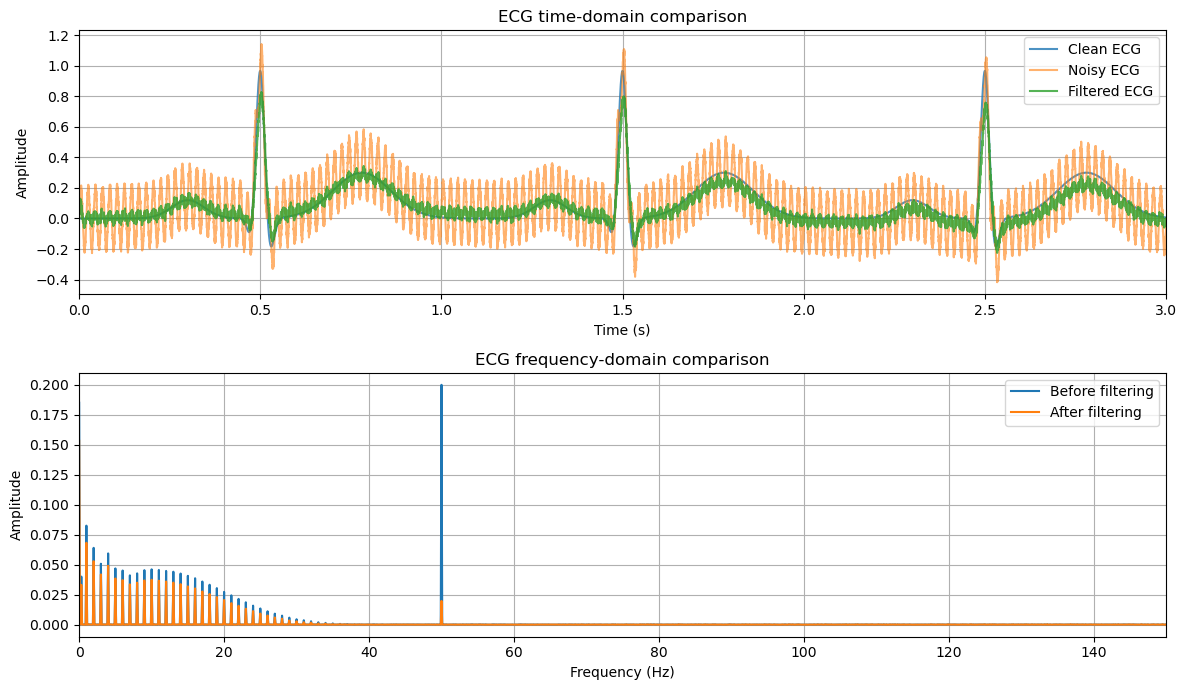

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(t_ecg, ecg_clean, label="Clean ECG", alpha=0.8)
axes[0].plot(t_ecg, ecg_noisy, label="Noisy ECG", alpha=0.6)
axes[0].plot(t_ecg, ecg_filtered, label="Filtered ECG", alpha=0.8)

axes[0].set_xlim(0, 3)
axes[0].set_title("ECG time-domain comparison")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude")
axes[0].legend()
axes[0].grid(True)

plot_spectrum(ecg_noisy, fs_ecg, "Before filtering", axes[1])
plot_spectrum(ecg_filtered, fs_ecg, "After filtering", axes[1])

axes[1].set_xlim(0, 150)
axes[1].set_title("ECG frequency-domain comparison")
axes[1].legend()

plt.tight_layout()
plt.show()

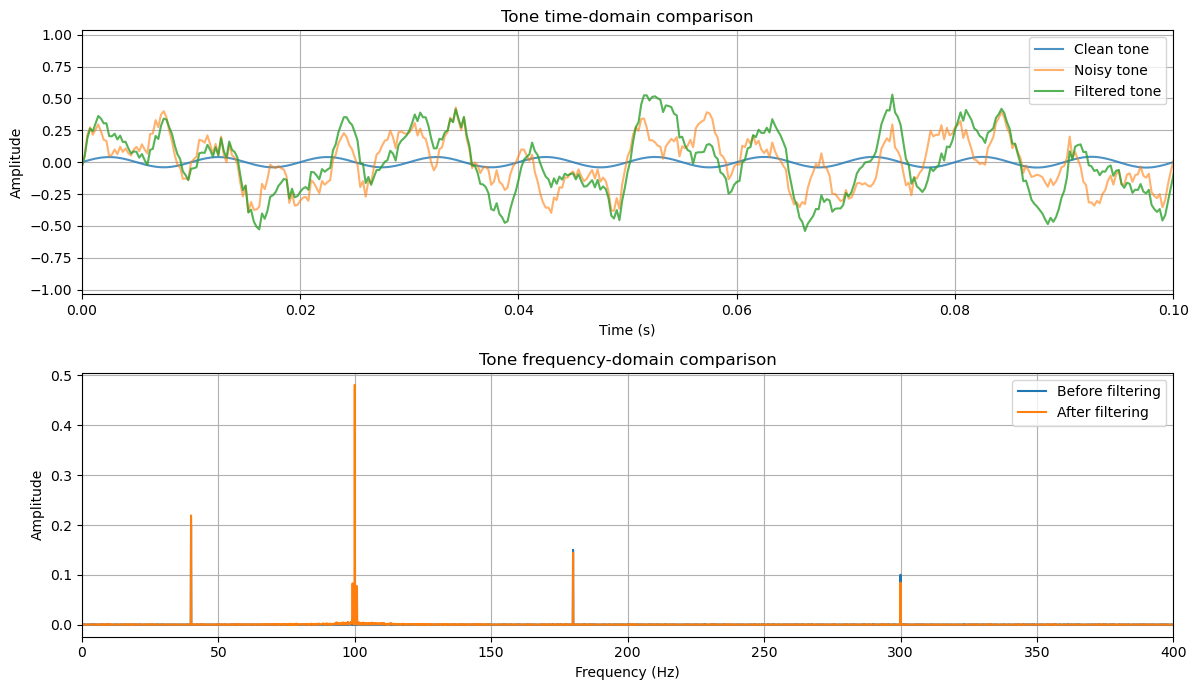

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(t_tone, tone_clean, label="Clean tone", alpha=0.8)
axes[0].plot(t_tone, tone_noisy, label="Noisy tone", alpha=0.6)
axes[0].plot(t_tone, tone_filtered, label="Filtered tone", alpha=0.8)

axes[0].set_xlim(0, 0.1)
axes[0].set_title("Tone time-domain comparison")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude")
axes[0].legend()
axes[0].grid(True)

plot_spectrum(tone_noisy, fs_tone, "Before filtering", axes[1])
plot_spectrum(tone_filtered, fs_tone, "After filtering", axes[1])

axes[1].set_xlim(0, 400)
axes[1].set_title("Tone frequency-domain comparison")
axes[1].legend()

plt.tight_layout()
plt.show()

In [11]:
mse_before = np.mean((ecg_noisy - ecg_clean)**2)
mse_after = np.mean((ecg_filtered - ecg_clean)**2)

mse_reduction = 100 * (mse_before - mse_after) / mse_before

print("ECG evaluation")
print(f"MSE before: {mse_before:.6f}")
print(f"MSE after:  {mse_after:.6f}")
print(f"MSE reduction: {mse_reduction:.2f}%")

ECG evaluation
MSE before: 0.021026
MSE after:  0.002597
MSE reduction: 87.65%


In [12]:
def amplitude_at_frequency(signal, fs, frequency):
    n = len(signal)

    frequencies = np.fft.rfftfreq(n, d=1/fs)
    spectrum = np.abs(np.fft.rfft(signal)) * 2 / n

    index = np.argmin(np.abs(frequencies - frequency))

    return spectrum[index]


amplitude_before = amplitude_at_frequency(
    tone_noisy, fs_tone, res_fc
)

amplitude_after = amplitude_at_frequency(
    tone_filtered, fs_tone, res_fc
)

measured_gain = amplitude_after / amplitude_before

print("Tone evaluation")
print(f"Amplitude before: {amplitude_before:.6f}")
print(f"Amplitude after:  {amplitude_after:.6f}")
print(f"Measured gain:    {measured_gain:.4f}")
print(f"Target gain:      {res_Gc:.4f}")

Tone evaluation
Amplitude before: 0.060166
Amplitude after:  0.481256
Measured gain:    7.9988
Target gain:      5.0000


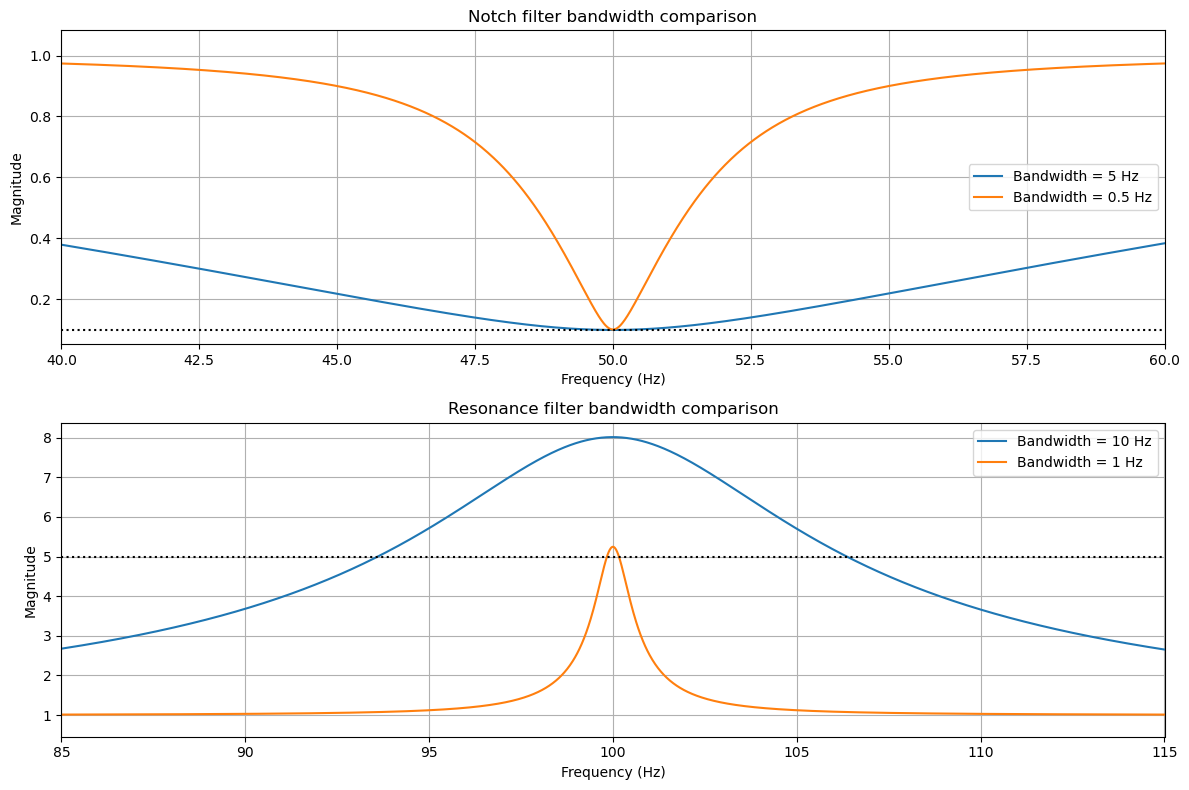

In [13]:
notch_bandwidths = [5, 0.5]
res_bandwidths = [10, 1]

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

for bandwidth in notch_bandwidths:

    wc = 2 * math.pi * notch_fc / fs_ecg
    B = 2 * math.pi * bandwidth / fs_ecg

    b, a = design_biquad_filter(
        notch_G0, notch_Gc, B, wc
    )

    frequencies, h = freqz(
        b, a, worN=131072, fs=fs_ecg
    )

    axes[0].plot(
        frequencies,
        np.abs(h),
        label=f"Bandwidth = {bandwidth} Hz"
    )

for bandwidth in res_bandwidths:

    wc = 2 * math.pi * res_fc / fs_tone
    B = 2 * math.pi * bandwidth / fs_tone

    b, a = design_biquad_filter(
        res_G0, res_Gc, B, wc
    )

    frequencies, h = freqz(
        b, a, worN=131072, fs=fs_tone
    )

    axes[1].plot(
        frequencies,
        np.abs(h),
        label=f"Bandwidth = {bandwidth} Hz"
    )

axes[0].axhline(notch_Gc, color="black", linestyle=":")
axes[0].set_xlim(40, 60)
axes[0].set_title("Notch filter bandwidth comparison")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Magnitude")
axes[0].legend()
axes[0].grid(True)

axes[1].axhline(res_Gc, color="black", linestyle=":")
axes[1].set_xlim(85, 115)
axes[1].set_title("Resonance filter bandwidth comparison")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Magnitude")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [14]:
from pathlib import Path

output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

wavfile.write(
    output_dir / "ecg_filtered.wav",
    fs_ecg,
    ecg_filtered.astype(np.float32)
)

wavfile.write(
    output_dir / "tone_filtered.wav",
    fs_tone,
    tone_filtered.astype(np.float32)
)

print("Filtered WAV files saved to output/")

Filtered WAV files saved to output/


## Conclusions

soon...